# Gaussian Processes — Duffing
## Identificação discreta com estados completos

**Projeto:** Data-Driven Dynamics and Control.  
**Origem:** extensão experimental nossa do estudo de GP; não é um experimento do artigo-base.

**Objetivo:** aprender a transição $x_{k+1}=F(x_k,u_k)$ usando dois GPs escalares, sem revelar ao identificador as equações do Duffing. Avaliar predição de um passo, rollout livre, generalização e incerteza.

**Fundamentos e reprodução do Exemplo 4.3:** [GP_Problema_1.ipynb](GP_Problema_1.ipynb).  
**Artigo-base:** [Control-Oriented System Identification: Classical, Learning, and Physics-Informed Approaches](https://arxiv.org/html/2512.06315).

Este notebook usa apenas NumPy, SciPy e Matplotlib. Execute as células de cima para baixo. Não há GPSSM, GP-NARX, redes neurais ou restrições de estabilidade.


## 1. Definindo a planta e o problema

Preservamos o benchmark modificado utilizado nos scripts de Koopman e SINDy do repositório:
$$
\frac{dq}{dt}=p,\qquad
\frac{dp}{dt}=-2p-q\cos(q+p)+u.
$$

Usamos $dt=0.01$ s e RK4, mantendo $u_k$ constante em cada intervalo. O **simulador** conhece as equações acima, mas o **identificador** observará somente
$$
z_k=[q_k,p_k,u_k]^\top\in\mathbb R^3,\qquad
x_{k+1}=[q_{k+1},p_{k+1}]^\top\in\mathbb R^2.
$$
Nossa escolha é predição direta do próximo estado, **não** do incremento.


In [39]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.linalg import cho_factor, cho_solve
from scipy.optimize import minimize

DT, DELTA = 0.01, 2.0
rng = np.random.default_rng(156)

def dynamics(x, u):
    """Exclusiva do simulador; não é passada ao GP."""
    q, p = x[...,0], x[...,1]
    return np.stack((p, -DELTA*p-q*np.cos(q+p)+u), axis=-1)

def simulate_step(x, u):
    """Passo RK4 com entrada constante; aceita amostras em lote."""
    k1 = dynamics(x,u)
    k2 = dynamics(x+DT*k1/2,u)
    k3 = dynamics(x+DT*k2/2,u)
    k4 = dynamics(x+DT*k3,u)
    return x+DT*(k1+2*k2+2*k3+k4)/6


## 2. Dados experimentais

Um GP exato exige fatoração da matriz $K\in\mathbb R^{N\times N}$, com custo aproximado $O(N^3)$. Por isso partimos de **400 transições independentes**, não das 40 mil usadas em Koopman.

Amostramos $q_k,p_k,u_k$ independentemente e uniformemente em $[-1,1]$, e integramos a planta por um passo para obter $x_{k+1}$.

Nesta primeira rodada não adicionamos ruído de medição. A regularização diagonal do GP, definida adiante, **não representa ruído de medição simulado**. Para uma comparação futura com Koopman, deveremos igualar número de dados e condições de avaliação.


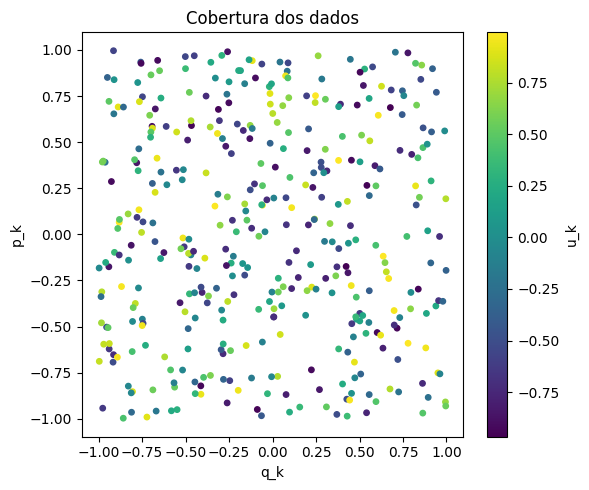

In [36]:
N_TRAIN = 400  # experiência futura: 150, 250 ou 600
X_train = rng.uniform(-1, 1, size=(N_TRAIN, 2))
U_train = rng.uniform(-1, 1, size=N_TRAIN)
Y_train = simulate_step(X_train, U_train)
Z_train = np.column_stack((X_train, U_train))

assert Z_train.shape == (N_TRAIN, 3) and Y_train.shape == (N_TRAIN, 2)

plt.figure(figsize=(6, 5))
sc = plt.scatter(X_train[:, 0], X_train[:, 1], c=U_train, s=15)
plt.colorbar(sc, label="u_k")
plt.xlabel("q_k")
plt.ylabel("p_k")
plt.title("Cobertura dos dados")
plt.tight_layout()
plt.show()

## 3. Dois GPs escalares com Matérn 3/2

Em vez de um modelo de saída vetorial, treinamos **dois GPs independentes**:
$$
q_{k+1}=f_q(z_k),\qquad p_{k+1}=f_p(z_k),
\quad f_q\sim\mathcal{GP}(m_q,k_q),\quad
f_p\sim\mathcal{GP}(m_p,k_p).
$$

Escolhemos Matérn 3/2 com escalas separadas (ARD):
$$
k(z,z')=\sigma_f^2(1+r)e^{-r},\qquad
r=\sqrt{3\sum_{d=1}^3\left(\frac{z_d-z_d'}{\ell_d}\right)^2}.
$$
Poderíamos escolher outros kernels, foi escolhido o matérn pois ele é uma função contínua, para funções suaves. Diferente do RBF clássico que são para funções extremamente suaves e infinitamente diferenciáveis.

As variáveis de entrada e saída serão padronizadas com **médias e desvios-padrão calculados somente no treinamento**. Em coordenadas padronizadas a média a priori é zero; nas unidades físicas ela equivale à média constante do conjunto de treinamento.

A matriz é regularizada por $\sigma_n^2 I$, com $\sigma_n=0.018$ em unidades **normalizadas de saída**. Como a planta gerou dados sem ruído, isso funciona aqui como um pequeno termo de regularização. Estimamos $\ell_q,\ell_p,\ell_u,\sigma_f$ pela verossimilhança marginal.


In [37]:

# 1. NORMALIZAÇÃO DOS DADOS

# Calcula a média de q, p e u nos 400 dados de treinamento.
Z_MEAN = Z_train.mean(axis=0)

# Calcula o desvio-padrão de q, p e u.
Z_SCALE = Z_train.std(axis=0)

# Normaliza os dados para trabalhar com escalas semelhantes.
Z_norm = (Z_train - Z_MEAN) / Z_SCALE

# 2. KERNEL MATÉRN 3/2

def matern32_ard(A, B, ell, sigma_f):
    """
    Calcula a covariância entre os pontos de A e B.

    A, B: conjuntos de entradas [q, p, u]
    ell: comprimentos de escala para q, p e u -> Para evitar problemas númericos
    sigma_f: amplitude do GP

    Retorna uma matriz de covariâncias.
    No treinamento, ela tem tamanho 400 x 400.
    """

    # Garante que A e B sejam matrizes NumPy.
    A = np.atleast_2d(np.asarray(A, float))
    B = np.atleast_2d(np.asarray(B, float))

    # Calcula as diferenças entre todos os pares de pontos.
    # Cada diferença é dividida pelo comprimento de escala.
    D = (A[:, None, :] - B[None, :, :]) / ell

    # Calcula a distância entre os pontos.
    r = np.sqrt(3 * np.sum(D * D, axis=-1))

    # Aplica a fórmula do kernel Matérn 3/2.
    return sigma_f**2 * (1 + r) * np.exp(-r)

# 3. CLASSE DO PROCESSO GAUSSIANO

class GPRegressor:
    """
    Um modelo de GP para prever uma única saída.

    Vamos criar dois objetos desta classe:
    um para q e outro para p.
    """

    def __init__(self, noise_std=0.018):
        # Regularização usada na matriz de covariância.
        self.noise_std = noise_std

    # 3.1. TREINAMENTO

    def fit(self, X, y):
        """
        X: entradas do GP -> [q, p, u]
        y: saída que queremos aprender -> q_proximo OU p_proximo
        """

        # Guarda as entradas de treinamento.
        self.X = np.asarray(X, float)

        # Organiza as saídas em um vetor.
        y = np.asarray(y, float).reshape(-1)

        # Calcula média e desvio-padrão das saídas.
        self.y_mean = y.mean()
        self.y_std = y.std()

        # Normaliza as saídas.
        self.y = (y - self.y_mean) / self.y_std

        # n = número de observações (400).
        # d = número de entradas (3).
        n, d = self.X.shape

        # 3.2. FUNÇÃO QUE AVALIA OS HIPERPARÂMETROS

        def nll(v, factors=False): # Negative Log Likelihood (nesse caso, marginal likelihood)
            """
            Mede quão bem os hiperparâmetros explicam
            os dados observados.

            Quanto MENOR o resultado, melhor o ajuste
            segundo a verossimilhança marginal.
            
            v contém quatro números que o otimizador está experimentando
                - ell_q: quanto a distância em \(q\) influencia a correlação.
                - ell_p: quanto a distância em \(p\) influencia a correlação.
                - ell_u: quanto a distância em \(u\) influencia a correlação.
                - sf: quanto a função pode variar em torno da sua média.
            """

            # Recupera os três comprimentos de escala.
            ell = np.exp(v[:d])

            # Recupera a amplitude do GP.
            sf = np.exp(v[d])

            # Constrói a matriz de covariância dos dados.
            K = matern32_ard(self.X, self.X, ell, sf)

            # Adiciona regularização à diagonal.
            K[np.diag_indices(n)] += self.noise_std**2 + 1e-7

            try:
                # Fatora a matriz usando Cholesky.
                # Isso facilita os cálculos seguintes.
                cf = cho_factor(
                    K, lower=True, check_finite=False
                )

                # Resolve um sistema linear usando os dados.
                # O resultado será utilizado nas predições.
                alpha = cho_solve(
                    cf, self.y, check_finite=False
                )

            except np.linalg.LinAlgError:
                # Penaliza configurações numericamente inválidas.
                return 1e12

            # Se solicitado, devolve os valores necessários
            # para realizar as predições.
            if factors:
                return ell, sf, cf, alpha

            # Calcula a negativa da log-verossimilhança marginal.
            # É a função que o otimizador tentará minimizar.
            return float(
                0.5 * self.y @ alpha # 1/2 y^T K^-1 y -> Os valores que observamos estão muito distantes do que esse GP considera normal?
                + np.log(np.diag(cf[0])).sum() # 1/2 Log(mod(K)) -> evita que o GP aumente indefinidamente sua variância apenas para tornar os valores observados pouco surpreendentes
                + n / 2 * np.log(2 * np.pi) # garantir que a densidade de probabilidade esteja corretamente normalizada
            )
        # 3.3. ESCOLHA AUTOMÁTICA DOS HIPERPARÂMETROS

        # Começamos com todos os hiperparâmetros iguais a 1.
        # O otimizador trabalha com os logaritmos deles.
        initial = np.log([1.0] * d + [1.0])

        # Procura hiperparâmetros que minimizem a função nll.
        result = minimize(
            nll,
            initial,
            method="L-BFGS-B", # Limited-memory Broyden–Fletcher–Goldfarb–Shanno with Bounds.
            bounds=[(-2.3, 2.3)] * d + [(-2.3, 2.3)],
            options={"maxiter": 55}
        )

        # Guarda os hiperparâmetros escolhidos e os cálculos
        # necessários para fazer previsões.
        self.ell, self.sf, self.cf, self.alpha = nll(
            result.x, True
        )

        # Guarda informações sobre a otimização.
        self.result = result

        return self

    # 3.4. PREDIÇÃO
    def predict(self, X):
        """
        Recebe novas entradas [q, p, u].

        Retorna:
        - valor médio previsto;
        - desvio-padrão da previsão.
        """

        # Organiza as novas entradas.
        X = np.atleast_2d(np.asarray(X, float))

        # Calcula a covariância entre as novas entradas
        # e os dados utilizados no treinamento.
        Ks = matern32_ard(
            X, self.X, self.ell, self.sf
        )

        # Calcula a média posterior.
        mu = Ks @ self.alpha

        # Cálculos necessários para obter a variância.
        V = cho_solve(
            self.cf, Ks.T, check_finite=False
        )

        # Calcula a variância posterior.
        var = np.maximum(
            0,
            self.sf**2 - np.sum(Ks * V.T, axis=1)
        )

        # Desfaz a normalização e retorna:
        # média prevista e desvio-padrão previsto.
        return (
            self.y_mean + self.y_std * mu,
            self.y_std * np.sqrt(var)
        )


# 4. CRIAÇÃO E TREINAMENTO DOS DOIS GPs

# Cria dois modelos independentes:
# gps[0] aprende a prever q_proximo.
# gps[1] aprende a prever p_proximo.

gps = [
    GPRegressor().fit(Z_norm, Y_train[:, j])
    for j in range(2)
]

# Mostra os hiperparâmetros encontrados.
for name, gp in zip(["q_{k+1}", "p_{k+1}"], gps):
    print(
        name,
        "ell=", np.round(gp.ell, 3),
        "sigma_f=", round(gp.sf, 3),
        "otimizador_sucesso=", gp.result.success
    )

# 5. FUNÇÃO PARA PREVER O PRÓXIMO ESTADO DO DUFFING
def gp_step(Z):
    """
    Recebe [q_atual, p_atual, u_atual].

    Retorna:
    1. Previsões de [q_proximo, p_proximo].
    2. Desvios-padrão dessas previsões.
    """

    # Normaliza as novas entradas da mesma forma
    # utilizada no treinamento.
    Zn = (
        np.atleast_2d(np.asarray(Z, float)) - Z_MEAN
    ) / Z_SCALE

    # Consulta os dois modelos treinados.
    results = [gp.predict(Zn) for gp in gps]

    # Junta os resultados dos dois GPs.
    return (
        np.column_stack([r[0] for r in results]),
        np.column_stack([r[1] for r in results])
    )


<>:82: SyntaxWarning: invalid escape sequence '\('
<>:82: SyntaxWarning: invalid escape sequence '\('
C:\Users\Igor Amoras\AppData\Local\Temp\ipykernel_23932\2116371054.py:82: SyntaxWarning: invalid escape sequence '\('
  """


q_{k+1} ell= [3.687 9.974 9.974] sigma_f= 0.405 otimizador_sucesso= True
p_{k+1} ell= [9.974 3.643 9.974] sigma_f= 0.404 otimizador_sucesso= True


## 4. O modelo

Na predição one-step, cada avaliação recebe o estado verdadeiro. No **rollout livre**, depois do estado inicial, usamos as **próprias predições**:
$$
\hat x_{k+1}=\hat F(\hat x_k,u_k).
$$

Utilizaremos a entrada $u_k=0.8\sin(0.2k)$, presente no experimento original de Koopman, durante 500 passos. Testaremos $x_0=[-0.6,0.6]^\top$, dentro da região de treino, e $x_0=[-0.6,1.4]^\top$, condição inicial histórica que começa **parcialmente fora**.


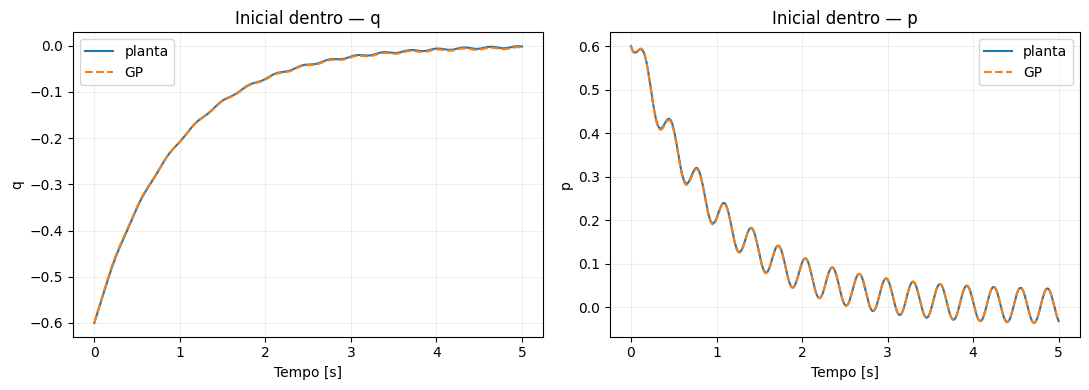

Inicial dentro RMSE do rollout [q,p]: [0.00171483 0.00129546]


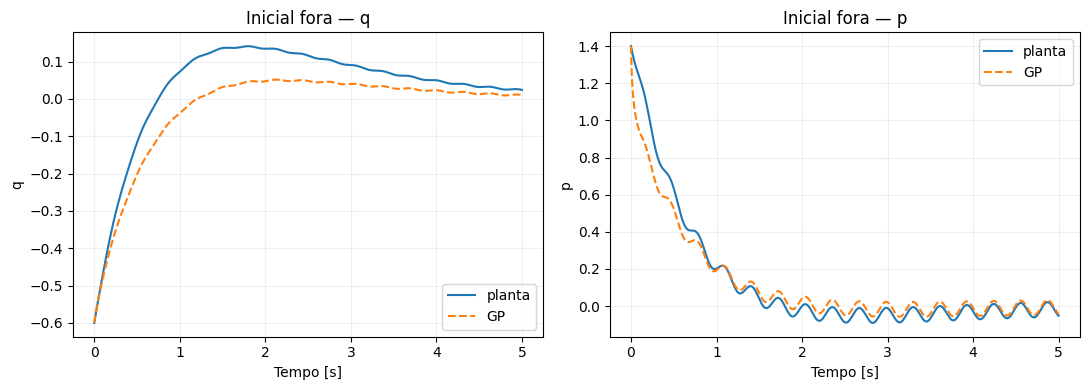

Inicial fora RMSE do rollout [q,p]: [0.06897693 0.07183248]


In [38]:

# 1. CONFIGURAÇÃO DA SIMULAÇÃO

N_ROLLOUT = 500  # Número de passos da simulação

# Entrada de controle senoidal aplicada tanto à planta quanto ao GP.
# np.arange(N_ROLLOUT) gera os índices k = 0, 1, ..., 499.
# A entrada em cada passo será u[k] = 0.8 * sin(0.2 * k).
U_roll = .8 * np.sin(.2 * np.arange(N_ROLLOUT))

def rmse(A, B):
    return np.sqrt(np.mean((A - B)**2, axis=0))


# 3. SIMULAÇÃO DA PLANTA E DO GP (ROLLOUT LIVRE)
def rollout(x0, U):
    # x0: estado inicial [q0, p0].
    # U: sequência de entradas de controle.
    # Vamos simular duas trajetórias:
    #   real      -> planta verdadeira (equações do Duffing)
    #   predicted -> modelo identificado por GP

    # Cria uma matriz para armazenar os estados reais.
    # Linhas: instantes de tempo (incluindo o estado inicial).
    # Colunas: posição q e velocidade p.
    real = np.empty((len(U) + 1, 2))

    # Cria uma matriz com as mesmas dimensões para o GP.
    predicted = np.empty_like(real)

    # Inicializa a planta verdadeira no estado x0.
    real[0] = np.asarray(x0, float)

    # Inicializa o GP no MESMO estado.
    # Assim, as duas trajetórias começam nas mesmas condições.
    predicted[0] = np.asarray(x0, float)

    # Percorre todos os instantes da simulação.
    # k: índice do passo atual.
    # u: entrada de controle aplicada nesse passo.
    for k, u in enumerate(U):

        # PLANTA VERDADEIRA:
        # Calcula o próximo estado utilizando as equações
        # diferenciais do Duffing, integradas com RK4.
        real[k + 1] = simulate_step(real[k], u)

        # MODELO GP:
        # Usa a posição e a velocidade PREVISTAS no passo anterior,
        # junto com a entrada de controle u.
        #
        # gp_step recebe [q_k, p_k, u_k].
        # Ele retorna:
        #   [0] -> matriz das médias previstas
        #   [1] -> matriz dos desvios-padrão
        #
        # [0][0] seleciona a primeira linha da matriz de médias,
        # isto é, o próximo estado previsto [q_(k+1), p_(k+1)].
        #
        # IMPORTANTE:
        # O GP NÃO recebe o estado verdadeiro durante o rollout.
        # Ele utiliza suas próprias previsões anteriores.

        # Neste rollout, o modelo opera em malha aberta:
        # após a condição inicial, todas as predições utilizam
        # exclusivamente os estados anteriormente previstos pelo GP.
        #
        # Em um sistema real, poderíamos utilizar medições dos estados
        # para corrigir as predições e reduzir o acúmulo de erros.
        predicted[k + 1] = gp_step(
            [[predicted[k, 0], predicted[k, 1], u]]
        )[0][0]

    # Retorna todas as posições e velocidades simuladas
    # pela planta verdadeira e pelo GP.
    return real, predicted


# 4. VISUALIZAÇÃO E AVALIAÇÃO DAS TRAJETÓRIAS
def plot_rollout(x0, title):

    # Executa o rollout a partir da condição inicial x0.
    real, pred = rollout(x0, U_roll)

    # Cria o vetor de tempo:
    # t = [0, DT, 2*DT, ..., N_ROLLOUT*DT].
    t = DT * np.arange(len(real))

    # Cria uma figura com dois gráficos lado a lado:
    #   1. Posição q ao longo do tempo
    #   2. Velocidade p ao longo do tempo
    fig, axes = plt.subplots(1, 2, figsize=(11, 4))

    # Percorre as duas variáveis de estado.
    # j=0 -> posição q
    # j=1 -> velocidade p
    for j, name in enumerate(["q", "p"]):

        # Trajetória da planta verdadeira (linha contínua).
        axes[j].plot(t, real[:, j], label="planta")

        # Trajetória prevista pelo GP (linha tracejada).
        axes[j].plot(t, pred[:, j], "--", label="GP")

        # Configura os nomes dos eixos e o título.
        axes[j].set(
            xlabel="Tempo [s]",
            ylabel=name,
            title=title + " — " + name
        )

        # Mostra a legenda e a grade.
        axes[j].legend()
        axes[j].grid(alpha=.2)

    # Ajusta o espaçamento e exibe os gráficos.
    plt.tight_layout()
    plt.show()

    # Calcula e imprime os erros ao longo de toda a trajetória.
    # O resultado contém um RMSE para q e outro para p.
    print(
        title,
        "RMSE do rollout [q,p]:",
        rmse(pred, real)
    )

    # Retorna as trajetórias caso queiramos analisá-las depois.
    return real, pred


# 5. EXECUÇÃO DOS EXPERIMENTOS

# EXPERIMENTO 1:
# Condição inicial dentro da região utilizada no treinamento.
# O GP já observou exemplos com q e p nessa faixa.
real_in, pred_in = plot_rollout(
    [-.6, .6],
    "Inicial dentro"
)

# EXPERIMENTO 2:
# Condição inicial parcialmente fora da região de treinamento.
# Durante o treino, p estava em [-1, 1].
# Aqui começamos com p = 1.4.
#
# Queremos observar como o GP se comporta ao extrapolar
# e como os erros podem se acumular durante o rollout.
real_out, pred_out = plot_rollout(
    [-.6, 1.4],
    "Inicial fora"
)


## 5. Efeito de ruído nas observações

Repetimos o treinamento com **1%, 3%, 5% e 10% de ruído gaussiano nas saídas** $[q_{k+1},p_{k+1}]$. Cada percentual indica o **desvio-padrão do ruído em relação ao desvio-padrão de cada saída de treinamento**. As entradas $[q_k,p_k,u_k]$ continuam sem ruído. Usamos a mesma realização aleatória, escalada para cada percentual, para facilitar a comparação.

Mantemos os mesmos 1.000 pontos, kernel Matérn, configuração de treinamento, entrada senoidal e estados iniciais. A planta usada para avaliar o rollout continua **sem ruído**. Comparamos o GP original (0%) e os quatro GPs treinados com ruído usando os gráficos de $q(t)$ e $p(t)$ e seus RMSEs.

> **Observação:** o termo `noise_std=0.018` do GP permanece fixo em todos os treinamentos; neste experimento variamos **apenas o ruído adicionado aos dados**. O ajuste de oito GPs com 1.000 amostras pode levar algum tempo.


Treinamento com 1% de ruído concluído.
Treinamento com 3% de ruído concluído.
Treinamento com 5% de ruído concluído.
Treinamento com 10% de ruído concluído.


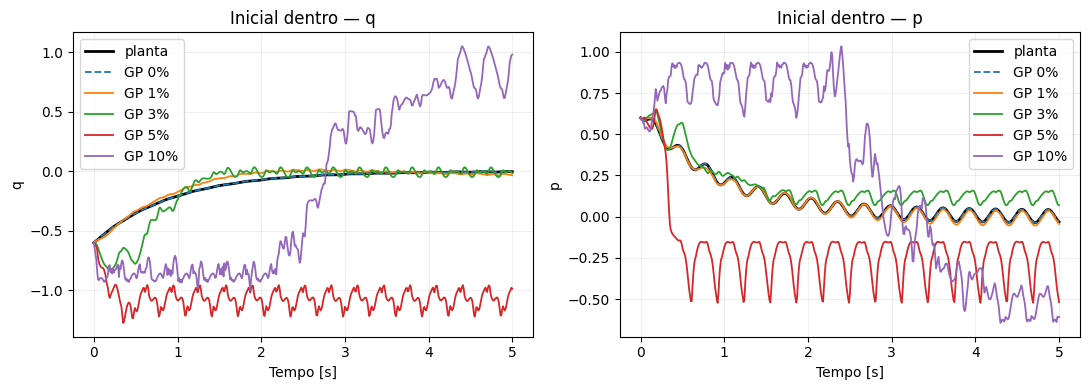


Inicial dentro — RMSE do rollout [q, p]:
GP  0%: q=0.000753  p=0.000384
GP  1%: q=0.037314  p=0.010478
GP  3%: q=0.116232  p=0.086402
GP  5%: q=0.972460  p=0.359081
GP 10%: q=0.631684  p=0.524916


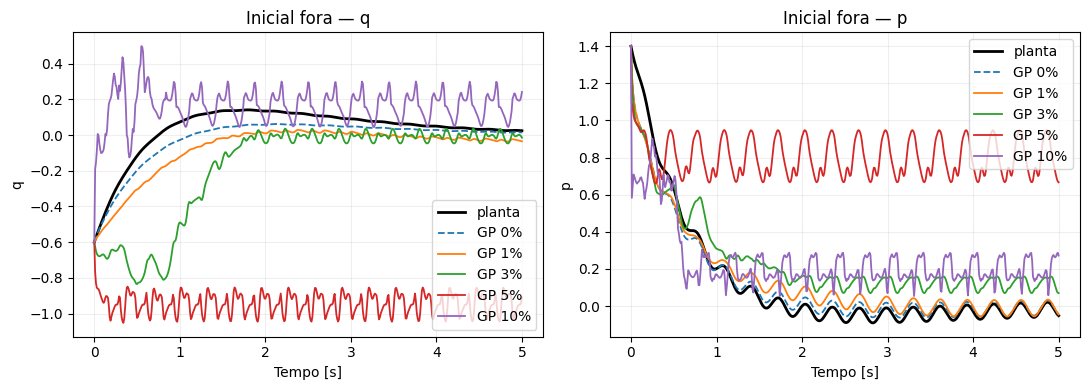


Inicial fora — RMSE do rollout [q, p]:
GP  0%: q=0.061578  p=0.062899
GP  1%: q=0.119117  p=0.077842
GP  3%: q=0.309139  p=0.162950
GP  5%: q=0.991330  p=0.741424
GP 10%: q=0.194982  p=0.236739


In [34]:
# 1. GERAÇÃO DOS DADOS COM RUÍDO
niveis_ruido = (1, 3, 5, 10)
rng_ruido = np.random.default_rng(2027)

# Cada porcentagem é relativa ao desvio-padrão de q_(k+1) e p_(k+1).
# Usamos a mesma amostra de ruído, multiplicada por 1%, 3%, 5% ou 10%.
ruido_base = rng_ruido.standard_normal(Y_train.shape)
escala_saida = Y_train.std(axis=0)

# 2. TREINAMENTO DOS QUATRO PARES DE GPs
gps_ruidosos = {}
for percentual in niveis_ruido:
    Y_com_ruido = Y_train + (percentual / 100) * ruido_base * escala_saida
    gps_ruidosos[percentual] = [
        GPRegressor().fit(Z_norm, Y_com_ruido[:, j])
        for j in range(2)
    ]
    print(f"Treinamento com {percentual}% de ruído concluído.")


# 3. ROLLOUT LIVRE DE UM PAR DE GPs
def rollout_gps(x0, U, modelos):
    predicted = np.empty((len(U) + 1, 2))
    predicted[0] = np.asarray(x0, float)

    for k, u in enumerate(U):
        # Normaliza [q, p, u] usando os dados originais de treinamento.
        z = (np.array([[predicted[k, 0], predicted[k, 1], u]]) - Z_MEAN) / Z_SCALE

        # Mesma média do método predict(), mas sem calcular a variância,
        # que não é necessária para desenhar estas trajetórias.
        predicted[k + 1] = [
            gp.y_mean + gp.y_std * (matern32_ard(z, gp.X, gp.ell, gp.sf) @ gp.alpha)[0]
            for gp in modelos
        ]

    return predicted


# 4. GRÁFICOS E COMPARAÇÃO DE ERROS
def comparar_ruidos(x0, titulo):
    # Planta verdadeira, sem ruído, com a mesma entrada senoidal.
    real = np.empty((len(U_roll) + 1, 2))
    real[0] = np.asarray(x0, float)
    for k, u in enumerate(U_roll):
        real[k + 1] = simulate_step(real[k], u)

    # 0%: GP original. Demais níveis: GPs treinados com dados ruidosos.
    previsoes = {0: rollout_gps(x0, U_roll, gps)}
    for percentual in niveis_ruido:
        previsoes[percentual] = rollout_gps(x0, U_roll, gps_ruidosos[percentual])

    t = DT * np.arange(len(real))
    fig, axes = plt.subplots(1, 2, figsize=(11, 4))

    for j, nome in enumerate(["q", "p"]):
        axes[j].plot(t, real[:, j], color="black", linewidth=2, label="planta")
        for percentual, pred in previsoes.items():
            axes[j].plot(
                t, pred[:, j],
                "--" if percentual == 0 else "-",
                linewidth=1.3, label=f"GP {percentual}%"
            )
        axes[j].set(xlabel="Tempo [s]", ylabel=nome, title=f"{titulo} — {nome}")
        axes[j].legend()
        axes[j].grid(alpha=.2)

    plt.tight_layout()
    plt.show()

    # RMSE de cada modelo em relação à MESMA trajetória verdadeira.
    print(f"\n{titulo} — RMSE do rollout [q, p]:")
    for percentual, pred in previsoes.items():
        erro = rmse(pred, real)
        print(f"GP {percentual:>2}%: q={erro[0]:.6f}  p={erro[1]:.6f}")

    return real, previsoes


# 5. OS MESMOS DOIS ESTADOS INICIAIS DO EXPERIMENTO ORIGINAL
real_ruido_in, pred_ruido_in = comparar_ruidos([-.6, .6], "Inicial dentro")
real_ruido_out, pred_ruido_out = comparar_ruidos([-.6, 1.4], "Inicial fora")


# 6. Próximos passos e hipóteses

## 6.1. Hipóteses — Resultados e melhorias da identificação atual

Implementamos dois GPs com kernel Matérn 3/2 para identificar a dinâmica discreta do Duffing:

$$
\hat{x}_{k+1}=\hat{F}_{GP}(x_k,u_k)
$$

**Observações:** o modelo reproduziu bem a dinâmica dentro da região de treinamento, mas apresentou maiores erros fora dela e sensibilidade ao ruído, especialmente durante simulações de múltiplos passos.

**Hipóteses para investigação:**

1. **Identificação por incrementos:** atualmente aprendemos diretamente $x_{k+1}$. Como $DT=0.01$, as diferenças entre estados consecutivos são pequenas. Podemos investigar se aprender $\Delta x_k=x_{k+1}-x_k$ melhora a identificação e o comportamento em simulações longas. Essa mudança, porém, não elimina o ruído das observações.

$$
\hat{x}_{k+1}=x_k+\widehat{\Delta x}_{GP}(x_k,u_k)
$$

2. **Escolha do kernel:** comparar Matérn 3/2, Matérn 5/2 e RBF, investigando como as hipóteses de suavidade influenciam precisão, extrapolação e erros acumulados.

3. **Tratamento do ruído:** avaliar o impacto da regularização fixa utilizada e comparar com a estimação da variância do ruído durante o treinamento.

4. **Cobertura dos dados:** investigar a influência da quantidade e da distribuição das amostras. Dados coletados em uma região limitada podem não representar adequadamente outras condições de operação.

Um ponto importante é que **minimizar a NLL não equivale a minimizar diretamente o erro acumulado da trajetória**. Também é necessário comparar os resultados com modelos simples, como a persistência.

## 6.2. GPs com propriedades estruturais

Em vez de aprender toda a dinâmica sem conhecimento prévio, podemos incorporar informações físicas ao modelo, seja por sua função média, pelo kernel ou pela parametrização da dinâmica.

Uma possibilidade é utilizar um modelo físico nominal e deixar o GP aprender apenas a parte desconhecida:

$$
\dot{x}=f_{\mathrm{nominal}}(x,u)+f_{GP}(x,u)
$$

Na formulação discreta que implementamos:

$$
\hat{x}_{k+1}=F_{\mathrm{nominal}}(x_k,u_k)+r_{GP}(x_k,u_k)
$$

O GP é treinado para aproximar o erro do modelo nominal:

$$
r_k=x_{k+1}-F_{\mathrm{nominal}}(x_k,u_k)
$$

**Possível vantagem:** reduzir a complexidade da função aprendida e aproveitar informações físicas que já conhecemos.

**Investigação:** verificar se o conhecimento parcial da dinâmica melhora a precisão, a generalização e a robustez ao ruído.

Existem ainda GPs estruturados por propriedades de energia, simetrias, sistemas Hamiltonianos e port-Hamiltonianos. Dependendo da formulação, determinadas propriedades podem ser preservadas por construção.

## 6.3. Gaussian Process State-Space Models (GP-SSM)

Nosso experimento utiliza estados completamente conhecidos. Entretanto, em sistemas reais, muitas vezes observamos apenas determinadas saídas.

Os GP-SSM permitem representar uma dinâmica probabilística em espaço de estados:

$$
x_{k+1}=f_{GP}(x_k,u_k)+w_k
$$

$$
y_k=h(x_k)+v_k
$$

Onde $w_k$ representa ruído de processo, $v_k$ representa ruído de medição e $x_k$ pode conter estados não diretamente observáveis.

**O que muda?** Além de aprender a dinâmica, precisamos estimar os estados internos a partir das medições disponíveis.

Isso pode envolver filtragem Bayesiana, suavização ou inferência variacional.

**Investigação:** utilizar apenas uma saída do Duffing, por exemplo $y_k=q_k$, e verificar se conseguimos identificar a dinâmica e reconstruir informações sobre o estado não medido.

É uma direção especialmente interessante para sistemas com observabilidade parcial, como modelos eletroquímicos de baterias.

## 6.4. GPs com estabilidade

Um GP convencional pode apresentar baixo erro de identificação sem garantir estabilidade das trajetórias previstas.

Existem abordagens que procuram incorporar ou verificar propriedades de estabilidade.

**Uma possibilidade é utilizar funções de Lyapunov**, analisando a dinâmica aprendida e suas incertezas:

$$
\dot V(x)=\nabla V(x)^\top\left(f_{\mathrm{nominal}}(x,u)+f_{GP}(x,u)\right)
$$

Para certificar estabilidade, precisaríamos demonstrar uma condição adequada de decrescimento de $V$, considerando limites válidos para o erro do GP.

Outra possibilidade, discutida na literatura de identificação de sistemas lineares, é construir kernels para respostas ao impulso que favoreçam ou garantam estabilidade BIBO, sob hipóteses específicas:

$$
y_k=\sum_{i=0}^{\infty}g_i u_{k-i}
$$

$$
\sum_{i=0}^{\infty}|g_i|<\infty
$$

**Investigação:** comparar um GP convencional com abordagens que incorporem propriedades de estabilidade, verificando o comportamento em simulações longas e regiões pouco amostradas.

É importante distinguir estabilidade garantida por construção de verificações probabilísticas condicionadas às hipóteses do modelo.

## 6.5. GPs Online

Atualmente, nosso GP é treinado offline. Durante o rollout, suas previsões não modificam o modelo.

Em aprendizado online, novas observações podem ser incorporadas ao conjunto de treinamento:

$$
\mathcal D_{k+1}
=
\mathcal D_k\cup\{(x_k,u_k,x_{k+1})\}
$$

Com isso, a distribuição preditiva pode ser atualizada para refletir novos dados, permitindo adaptação a mudanças na dinâmica.

**Principal dificuldade:** o custo computacional. Em GPs exatos, a fatoração da matriz de covariância possui custo da ordem de $O(N^3)$ no treinamento convencional.

Para viabilizar atualizações frequentes, a literatura investiga GPs esparsos, pontos indutores, janelas de dados e aproximações incrementais.

**Investigação:** simular mudanças nos parâmetros do Duffing durante a operação e avaliar se um GP atualizado online consegue acompanhar a nova dinâmica melhor do que o modelo treinado inicialmente.

## 6.6. Para além dessas abordagens

Outras possibilidades relevantes incluem:

- **GP-NARX:** identificação baseada em históricos de entradas e saídas, sem exigir medição direta de todos os estados.
- **Deep Gaussian Processes:** composição de processos gaussianos em múltiplas camadas, aumentando a flexibilidade da representação.
- **GPs espaço-temporais:** modelagem de comportamentos que variam tanto com o estado quanto com o tempo.
- **Active Learning:** seleção de novas amostras com base na incerteza do GP, buscando dados mais informativos para identificação.
- **GP-MPC:** utilização das previsões e da incerteza do GP em controle preditivo, incluindo tratamento de restrições e robustez.

**Direção proposta:** começar investigando as hipóteses da seção 6.1, mantendo o Duffing e as condições experimentais atuais. Posteriormente, explorar GP-SSM, modelos estruturados e abordagens com estabilidade, visando conectar identificação probabilística com técnicas clássicas de controle.